# 01 - Simulating a CBC signal and matched-filter SNR

Inject a coherent `IMRPhenomD` binary-black-hole signal (9 + 8 M$_\odot$, 200 Mpc) into coloured Gaussian noise
in a three-detector network (L1, H1, V1), whiten and band-pass it, and compute the matched-filter SNR.

All parameters live in `configs/default.yaml`; all logic lives in the `gwhht` package.

In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import numpy as np
import matplotlib.pyplot as plt
from gwhht.config import load_config
from gwhht.simulate import simulate_network
from gwhht.preprocess import preprocess_network
%matplotlib inline
from gwhht.snr import matched_filter_snr
from gwhht import plotting as P

In [2]:
cfg = load_config("../configs/default.yaml")
sim = simulate_network(cfg)
print(f"in-band duration: {sim.signal_duration:.2f} s | segment length: {sim.seglen} s | trigger GPS: {sim.t_trigger:.3f}")

in-band duration: 55.87 s | segment length: 64 s | trigger GPS: 1367469610.870


## Whitening and band-pass
Data are divided by the amplitude spectral density of each detector (aLIGO design for L1/H1, AdV design for V1) and band-passed to 15-250 Hz.

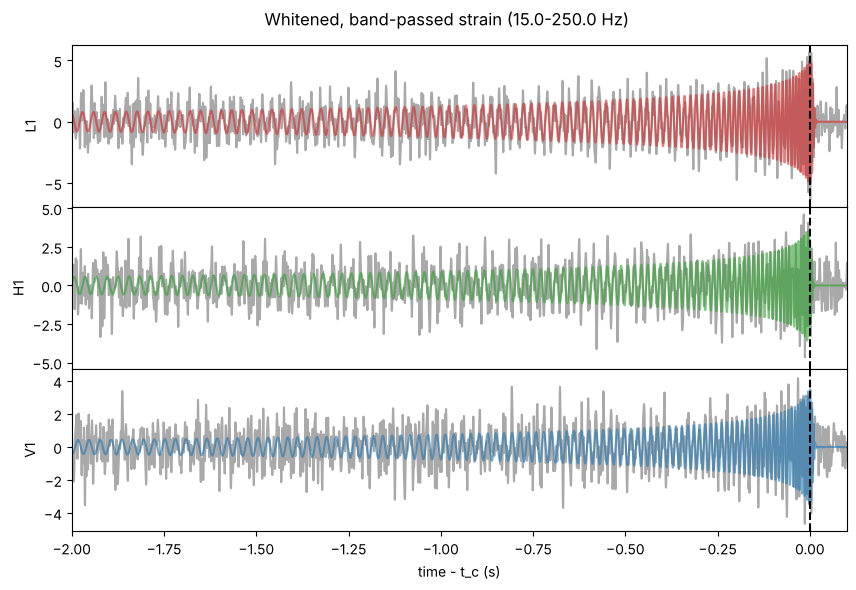

In [3]:
signal_wbp, data_wbp = preprocess_network(sim)
P.plot_strain(data_wbp, signal_wbp, cfg.ifos, sim.t_trigger, cfg.fband)
plt.show()

## Matched-filter SNR
The injected waveform is used as the template, so this is the optimal (best-case) SNR.

L1: 42.4
H1: 28.6
V1: 24.2
network SNR ~ 56.6


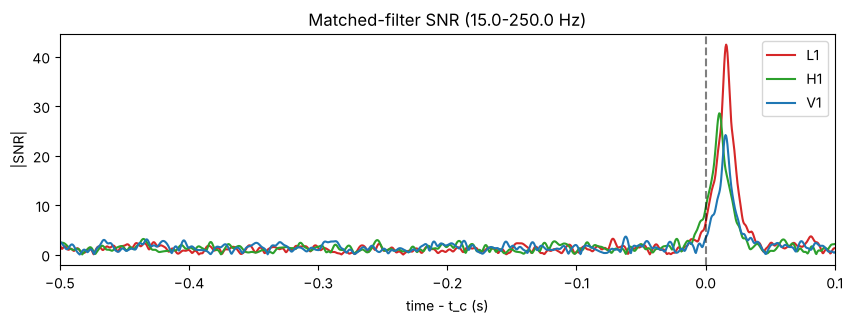

In [4]:
snr_series, snr_peak, snr_net = matched_filter_snr(sim)
for ifo, v in snr_peak.items():
    print(f"{ifo}: {v:.1f}")
print(f"network SNR ~ {snr_net:.1f}")
P.plot_snr(snr_series, cfg.ifos, sim.t_trigger, cfg.fband)
plt.show()

## Reproducibility
Noise is drawn with an explicit per-detector seed (`seed + k`), so the same seed always gives the same data.

In [5]:
a = simulate_network(cfg, seed=5).data_fd["L1"]
b = simulate_network(cfg, seed=5).data_fd["L1"]
print("identical for the same seed:", np.array_equal(np.asarray(a), np.asarray(b)))

identical for the same seed: True
